In [1]:
import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

In [2]:
# Locate project root automatically
candidates = [Path.cwd(), Path.cwd().parent]
project_root = next(
    p for p in candidates
    if (p / "data/Archive/small_images/noisy").exists()
)
base_path = project_root / "data/Archive/small_images"
noisy_path = base_path / "noisy"
gt_path = base_path / "gt"
print("Project root:", project_root)
print("Noisy folder:", noisy_path)
print("GT folder:", gt_path)

Project root: C:\Users\learn\Microscopy-Denoising
Noisy folder: C:\Users\learn\Microscopy-Denoising\data\Archive\small_images\noisy
GT folder: C:\Users\learn\Microscopy-Denoising\data\Archive\small_images\gt


In [3]:
noisy_files = sorted(
    f for f in os.listdir(noisy_path)
    if f.lower().endswith((".tif", ".tiff"))
)
gt_files = sorted(
    f for f in os.listdir(gt_path)
    if f.lower().endswith((".tif", ".tiff"))
)
assert noisy_files == gt_files, "Image pairs do not match!"
pairs = []
for filename in noisy_files:
    pairs.append({
        "filename": filename,
        "noisy_path": str(
            noisy_path / filename
        ),
        "gt_path": str(
            gt_path / filename
        )
    })
pairs_df = pd.DataFrame(pairs)
print("Total image pairs:", len(pairs_df))
display(pairs_df.head())

Total image pairs: 2457


,filename,noisy_path,gt_path
0,1000.tif,C:\Users\learn\Microscopy-Denoising\data\Archi...,C:\Users\learn\Microscopy-Denoising\data\Archi...
1,1001.tif,C:\Users\learn\Microscopy-Denoising\data\Archi...,C:\Users\learn\Microscopy-Denoising\data\Archi...
2,1002.tif,C:\Users\learn\Microscopy-Denoising\data\Archi...,C:\Users\learn\Microscopy-Denoising\data\Archi...
3,1003.tif,C:\Users\learn\Microscopy-Denoising\data\Archi...,C:\Users\learn\Microscopy-Denoising\data\Archi...
4,1004.tif,C:\Users\learn\Microscopy-Denoising\data\Archi...,C:\Users\learn\Microscopy-Denoising\data\Archi...


In [5]:
%pip install scikit-learn


  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- --

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
from sklearn.model_selection import train_test_split

print("Scikit-learn installed successfully!")

Scikit-learn installed successfully!


In [8]:
# First: Separate training data (70%) from remaining data (30%)

train_df, temp_df = train_test_split(
    pairs_df,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

# Second: Divide remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training samples: 1719
Validation samples: 369
Testing samples: 369
Total: 2457


In [9]:
train_names = set(train_df["filename"])
val_names = set(val_df["filename"])
test_names = set(test_df["filename"])

print("Train-Val overlap:", len(train_names & val_names))
print("Train-Test overlap:", len(train_names & test_names))
print("Val-Test overlap:", len(val_names & test_names))

assert train_names.isdisjoint(val_names)
assert train_names.isdisjoint(test_names)
assert val_names.isdisjoint(test_names)

print("\nAll splits are mutually exclusive!")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

All splits are mutually exclusive!


In [10]:
split_dir = project_root / "outputs" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

train_df[["filename"]].to_csv(
    split_dir / "train.csv", index=False
)

val_df[["filename"]].to_csv(
    split_dir / "validation.csv", index=False
)

test_df[["filename"]].to_csv(
    split_dir / "test.csv", index=False
)

print("Dataset splits saved successfully!")

Dataset splits saved successfully!


In [11]:
# Calculate intensity statistics using training images only

noisy_pixels = []
gt_pixels = []

for _, row in tqdm(train_df.iterrows(), total=len(train_df)):

    noisy = tifffile.imread(row["noisy_path"]).astype(np.float32)
    clean = tifffile.imread(row["gt_path"]).astype(np.float32)

    noisy_pixels.append(noisy.ravel())
    gt_pixels.append(clean.ravel())

noisy_pixels = np.concatenate(noisy_pixels)
gt_pixels = np.concatenate(gt_pixels)

print("NOISY IMAGE STATISTICS")
print("99th percentile:", np.percentile(noisy_pixels, 99))
print("99.5th percentile:", np.percentile(noisy_pixels, 99.5))
print("99.9th percentile:", np.percentile(noisy_pixels, 99.9))
print("Maximum:", noisy_pixels.max())

print("\nGROUND TRUTH STATISTICS")
print("99th percentile:", np.percentile(gt_pixels, 99))
print("99.5th percentile:", np.percentile(gt_pixels, 99.5))
print("99.9th percentile:", np.percentile(gt_pixels, 99.9))
print("Maximum:", gt_pixels.max())

100%|██████████| 1719/1719 [01:01<00:00, 28.00it/s]


NOISY IMAGE STATISTICS
99th percentile: 50.0
99.5th percentile: 57.0
99.9th percentile: 78.0
Maximum: 190.0

GROUND TRUTH STATISTICS
99th percentile: 1310.0
99.5th percentile: 1492.0
99.9th percentile: 2252.0
Maximum: 4095.0


In [12]:
# Calculate fixed normalization constants from training data

NOISY_SCALE = float(
    np.percentile(noisy_pixels, 99.9)
)

GT_SCALE = float(
    np.percentile(gt_pixels, 99.9)
)

print("Noisy normalization scale:", NOISY_SCALE)
print("Ground truth normalization scale:", GT_SCALE)

Noisy normalization scale: 78.0
Ground truth normalization scale: 2252.0


In [13]:
def normalize_noisy(image):
    image = image.astype(np.float32)
    return image / NOISY_SCALE


def normalize_gt(image):
    image = image.astype(np.float32)
    return image / GT_SCALE


def denormalize_gt(image):
    return image * GT_SCALE

In [14]:
# Load one training image pair

sample = train_df.iloc[0]

noisy = tifffile.imread(
    sample["noisy_path"]
)

clean = tifffile.imread(
    sample["gt_path"]
)

# Normalize
noisy_norm = normalize_noisy(noisy)
clean_norm = normalize_gt(clean)

print("Noisy normalized range:",
      noisy_norm.min(), noisy_norm.max())

print("GT normalized range:",
      clean_norm.min(), clean_norm.max())

print("Noisy dtype:", noisy_norm.dtype)
print("GT dtype:", clean_norm.dtype)

Noisy normalized range: 0.0 1.3205128
GT normalized range: 0.05550622 1.2078153
Noisy dtype: float32
GT dtype: float32


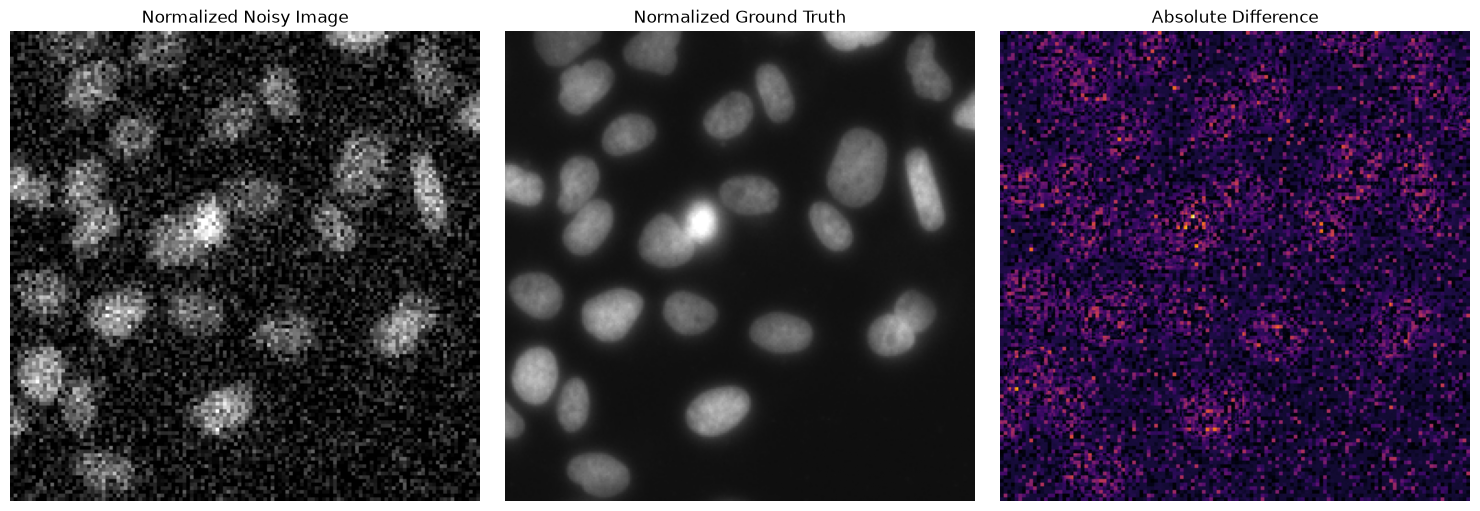

In [15]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(noisy_norm, cmap="gray", vmin=0, vmax=1)
plt.title("Normalized Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(clean_norm, cmap="gray", vmin=0, vmax=1)
plt.title("Normalized Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    np.abs(clean_norm - noisy_norm),
    cmap="inferno"
)
plt.title("Absolute Difference")
plt.axis("off")

plt.tight_layout()
plt.show()